# Super-Convergence на CIFAR-10

Студент: Заволович Богдан

In [16]:
import json
import platform
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from IPython.display import display
from torch import nn
from torch.optim.lr_scheduler import MultiStepLR, OneCycleLR
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import CIFAR10

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print("Device:", device, "| PyTorch:", torch.__version__)


Device: cuda | PyTorch: 2.11.0+cu130


In [17]:
seeds = [42]
batch_size = 128
num_workers = 2
baseline_epochs = 60
cycle_epochs = 20
baseline_lr = 0.1
max_lr = 0.5
weight_decay = 1e-4
target_acc = 85.0

out = Path("results_cifar10") / time.strftime("%Y%m%d_%H%M%S")
out.mkdir(parents=True, exist_ok=True)


In [18]:
normalize = transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    normalize,
])
test_transform = transforms.Compose([transforms.ToTensor(), normalize])

train_set = CIFAR10("data", train=True, download=True, transform=train_transform)
test_set = CIFAR10("data", train=False, download=True, transform=test_transform)
test_loader = DataLoader(
    test_set, batch_size=512, shuffle=False, num_workers=num_workers,
    persistent_workers=num_workers > 0, pin_memory=device.type == "cuda",
)
print("Train:", len(train_set), "| Test:", len(test_set))


Train: 50000 | Test: 10000


In [19]:
class Block(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(cout), nn.ReLU(),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout),
        )
        self.skip = nn.Identity()
        if stride != 1 or cin != cout:
            self.skip = nn.Sequential(
                nn.Conv2d(cin, cout, 1, stride=stride, bias=False),
                nn.BatchNorm2d(cout),
            )

    def forward(self, x):
        return torch.relu(self.body(x) + self.skip(x))


def make_model():
    model = nn.Sequential(
        nn.Conv2d(3, 16, 3, padding=1, bias=False),
        nn.BatchNorm2d(16), nn.ReLU(),
        Block(16, 16), Block(16, 16), Block(16, 16),
        Block(16, 32, 2), Block(32, 32), Block(32, 32),
        Block(32, 64, 2), Block(64, 64), Block(64, 64),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, 10),
    )
    for layer in model.modules():
        if isinstance(layer, nn.Conv2d):
            nn.init.kaiming_normal_(layer.weight, mode="fan_out", nonlinearity="relu")
    return model


## Обучение

step: LR 0.1 - 0.01 - 0.001

1cycle: LR 0.05 - 0.5 - 0.05 - 0.000005

In [20]:
def train(method, seed, epochs):
    torch.manual_seed(seed)
    model = make_model().to(device)
    loader = DataLoader(
        train_set, batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(seed),
        pin_memory=device.type == "cuda", num_workers=num_workers,
        persistent_workers=num_workers > 0,
    )
    optimizer = torch.optim.SGD(
        model.parameters(), lr=baseline_lr, momentum=0.9, weight_decay=weight_decay
    )
    if method == "step":
        scheduler = MultiStepLR(
            optimizer, milestones=[int(epochs * 0.5), int(epochs * 0.75)], gamma=0.1
        )
    else:
        scheduler = OneCycleLR(
            optimizer, max_lr=max_lr, epochs=epochs, steps_per_epoch=len(loader),
            pct_start=0.45, anneal_strategy="linear", three_phase=True,
            div_factor=10, final_div_factor=1e4,
            base_momentum=0.85, max_momentum=0.95,
        )

    loss_fn = nn.CrossEntropyLoss()
    history, rates = [], []
    train_seconds = 0.0
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum = torch.zeros((), device=device)
        if device.type == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            rates.append({
                "method": method, "seed": seed, "step": len(rates) + 1,
                "epoch": len(rates) / len(loader),
                "lr": optimizer.param_groups[0]["lr"],
                "momentum": optimizer.param_groups[0]["momentum"],
            })
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()
            if method == "1cycle" and len(rates) < epochs * len(loader):
                scheduler.step()
            loss_sum += loss.detach() * len(y)
        if device.type == "cuda":
            torch.cuda.synchronize()
        train_seconds += time.perf_counter() - start
        if method == "step":
            scheduler.step()

        model.eval()
        test_loss = torch.zeros((), device=device)
        correct = torch.zeros((), device=device)
        with torch.no_grad():
            for x, y in test_loader:
                x, y = x.to(device), y.to(device)
                logits = model(x)
                test_loss += loss_fn(logits, y) * len(y)
                correct += (logits.argmax(1) == y).sum()
        row = {
            "method": method, "seed": seed, "epoch": epoch, "step": len(rates),
            "train_loss": loss_sum.item() / len(train_set),
            "test_loss": test_loss.item() / len(test_set),
            "test_acc": 100 * correct.item() / len(test_set),
            "train_seconds": train_seconds,
        }
        if not np.isfinite([row["train_loss"], row["test_loss"]]).all():
            raise RuntimeError(f"Loss is not finite: {method}, seed={seed}, epoch={epoch}")
        history.append(row)
        pd.DataFrame(history).to_csv(out / f"{method}_{seed}.csv", index=False)
        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            print(f"{method}, seed={seed}, epoch={epoch:2d}: "
                  f"acc={row['test_acc']:.2f}%, train={train_seconds:.1f}s")

    rates = pd.DataFrame(rates)
    rates.to_csv(out / f"lr_{method}_{seed}.csv", index=False)
    return pd.DataFrame(history), rates


In [21]:
config = {
    "dataset": "CIFAR-10", "model": "ResNet-20",
    "seeds": seeds, "batch_size": batch_size, "num_workers": num_workers,
    "baseline_epochs": baseline_epochs, "cycle_epochs": cycle_epochs,
    "baseline_lr": baseline_lr, "max_lr": max_lr,
    "weight_decay": weight_decay, "target_acc": target_acc,
    "step_milestones": [int(baseline_epochs * 0.5), int(baseline_epochs * 0.75)],
    "step_gamma": 0.1, "step_momentum": 0.9,
    "cycle_pct_start": 0.45, "cycle_momentum": [0.85, 0.95],
    "cycle_three_phase": True, "cycle_annealing": "linear",
    "cycle_div_factor": 10, "final_div_factor": 1e4,
    "augmentation": "RandomCrop(32, padding=4), RandomHorizontalFlip(0.5)",
    "normalization_mean": [0.5, 0.5, 0.5], "normalization_std": [0.5, 0.5, 0.5],
    "train_size": len(train_set), "test_size": len(test_set),
    "python": platform.python_version(), "torch": torch.__version__,
    "torchvision": torchvision.__version__, "device": str(device),
    "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else None,
}
(out / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")

histories, schedules = [], []
for seed in seeds:
    for method, epochs in [("step", baseline_epochs), ("1cycle", cycle_epochs)]:
        h, s = train(method, seed, epochs)
        histories.append(h)
        schedules.append(s)
history = pd.concat(histories, ignore_index=True)
rates = pd.concat(schedules, ignore_index=True)
history.to_csv(out / "history.csv", index=False)


step, seed=42, epoch= 1: acc=52.18%, train=23.1s
step, seed=42, epoch= 5: acc=72.85%, train=110.0s
step, seed=42, epoch=10: acc=79.33%, train=219.3s
step, seed=42, epoch=15: acc=80.19%, train=328.4s
step, seed=42, epoch=20: acc=81.77%, train=437.3s
step, seed=42, epoch=25: acc=84.91%, train=549.1s
step, seed=42, epoch=30: acc=84.41%, train=668.4s
step, seed=42, epoch=35: acc=89.98%, train=791.3s
step, seed=42, epoch=40: acc=90.02%, train=913.1s
step, seed=42, epoch=45: acc=90.15%, train=1034.0s
step, seed=42, epoch=50: acc=90.34%, train=1154.0s
step, seed=42, epoch=55: acc=90.36%, train=1273.1s
step, seed=42, epoch=60: acc=90.34%, train=1391.5s
1cycle, seed=42, epoch= 1: acc=48.32%, train=23.6s
1cycle, seed=42, epoch= 5: acc=70.31%, train=118.1s
1cycle, seed=42, epoch=10: acc=79.69%, train=234.2s
1cycle, seed=42, epoch=15: acc=81.52%, train=351.2s
1cycle, seed=42, epoch=20: acc=89.05%, train=463.9s


## Результаты


In [22]:
rows = []
for (method, seed), h in history.groupby(["method", "seed"], sort=False):
    last = h.iloc[-1]
    equal_budget = h[h.epoch == cycle_epochs]
    reached = h[h.test_acc >= target_acc]
    rows.append({
        "method": method, "seed": seed, "epochs": int(last.epoch),
        "test_acc": last.test_acc,
        "acc_at_cycle_epochs": equal_budget.test_acc.iloc[0] if len(equal_budget) else np.nan,
        "train_seconds": last.train_seconds,
        "epochs_to_target": reached.epoch.iloc[0] if len(reached) else np.nan,
        "seconds_to_target": reached.train_seconds.iloc[0] if len(reached) else np.nan,
    })
results = pd.DataFrame(rows)
results.to_csv(out / "results.csv", index=False)
display(results.round(3))

summary = results.groupby("method")[[
    "test_acc", "acc_at_cycle_epochs", "train_seconds"
]].agg(["mean", "std"])
summary.to_csv(out / "summary.csv")
display(summary.round(3))


,method,seed,epochs,test_acc,acc_at_cycle_epochs,train_seconds,epochs_to_target,seconds_to_target
0,step,42,60,90.34,81.77,1391.470,24,525.392
1,1cycle,42,20,89.05,89.05,463.873,18,418.188


test_acc     acc_at_cycle_epochs     train_seconds    
           mean std                mean std          mean std
method                                                       
1cycle    89.05 NaN               89.05 NaN       463.873 NaN
step      90.34 NaN               81.77 NaN      1391.470 NaN

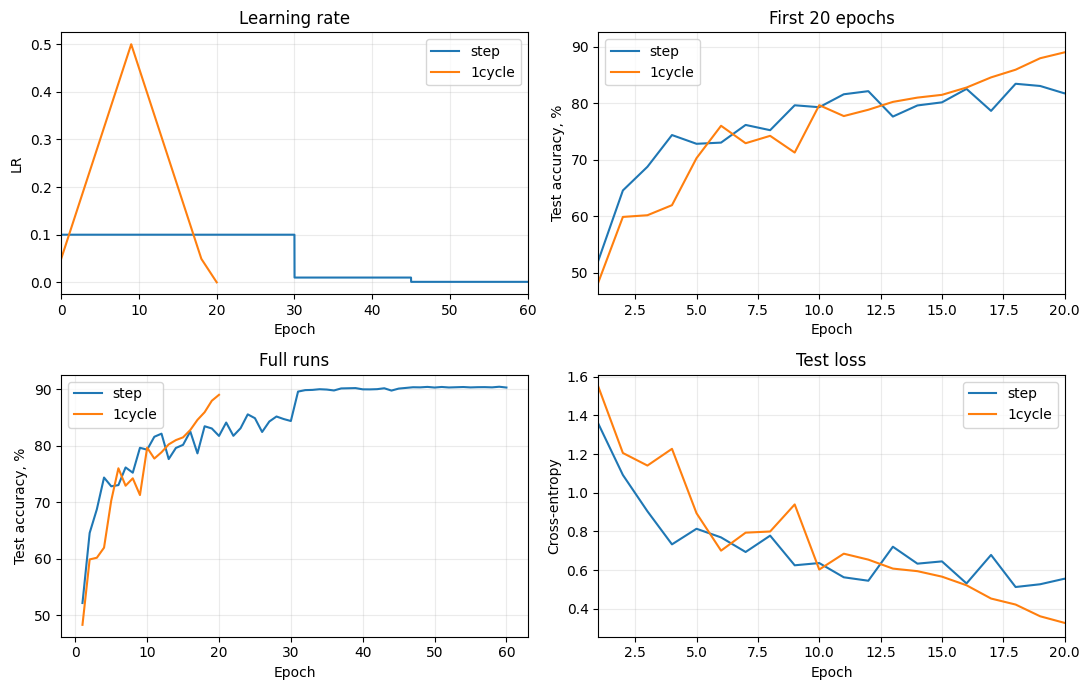

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for method, color in [("step", "tab:blue"), ("1cycle", "tab:orange")]:
    s = rates[(rates.method == method) & (rates.seed == seeds[0])]
    axes[0, 0].plot(s.epoch, s.lr, label=method, color=color)
    h = history[history.method == method].groupby("epoch")
    acc = h.test_acc.agg(["mean", "std"])
    for ax in [axes[0, 1], axes[1, 0]]:
        ax.plot(acc.index, acc["mean"], label=method, color=color)
        if len(seeds) > 1:
            ax.fill_between(acc.index, acc["mean"] - acc["std"],
                            acc["mean"] + acc["std"], color=color, alpha=0.15)
    test_loss = h.test_loss.mean()
    axes[1, 1].plot(test_loss.index, test_loss, label=method, color=color)

axes[0, 0].set(title="Learning rate", ylabel="LR", xlim=(0, max(baseline_epochs, cycle_epochs)))
axes[0, 1].set(title=f"First {cycle_epochs} epochs", ylabel="Test accuracy, %",
               xlim=(1, cycle_epochs))
axes[1, 0].set(title="Full runs", ylabel="Test accuracy, %")
axes[1, 1].set(title="Test loss", ylabel="Cross-entropy", xlim=(1, cycle_epochs))
for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
fig.savefig(out / "curves.png", dpi=180)
fig.savefig(out / "curves.pdf")
plt.show()
